In [1]:
!pip install tushare
!pip install chart-studio

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple


In [2]:
import numpy as np # 数学计算
import pandas as pd # 数据处理, 读取 CSV 文件 (e.g. pd.read_csv)
import matplotlib.pyplot as plt
from datetime import datetime as dt

import tushare as ts
import pandas as pd
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV


## 读取数据

In [4]:
# 设置Tushare token
# ts.set_token('xx')  # 替换为你的Tushare Token
# pro = ts.pro_api()
# stock_list = ['002847.SZ','002555.SZ','000951.SZ','603259.SH','600879.SH','601939.SH',
#               '000876.SZ','600031.SH','600754.SH','603833.SH','603126.SH','603899.SH','601088.SH',
#               '603877.SH','600233.SH']

# df = pd.DataFrame()
# for code in stock_list:
#     # 获取股票数据
#     df_tmp = pro.daily(ts_code=code, start_date='20200101', end_date='20221231')
#     df = pd.concat([df, df_tmp], axis=0)
    
# print(df.shape)

# df.head()

df = pd.read_csv('./data/stock_daily.csv',encoding='utf8')
print(df.shape)
df.tail()

(10914, 17)


,ts_code,trade_date,open,high,low,close,pre_close,change,pct_chg,vol,amount,return,lag_1,lag_2,lag_3,lag_4,lag_5
10909,601939.SH,2022-12-30,5.62,5.65,5.59,5.63,5.59,0.04,0.7156,402966.14,226544.203,-0.953674,-0.002135,8.567164,-0.842723,4.370936,-0.174699
10910,603833.SH,2022-12-30,121.30,122.89,119.01,121.53,121.79,-0.26,-0.2135,12350.79,149986.967,-0.002135,8.567164,-0.842723,4.370936,-0.174699,-0.686416
10911,000876.SZ,2022-12-30,12.73,12.91,12.66,12.91,12.73,0.18,1.4140,188291.15,240821.398,-0.840617,1.932657,-0.497636,7.002911,-0.882262,7.580882
10912,000951.SZ,2022-12-30,15.10,15.28,14.72,14.84,15.07,-0.23,-1.5262,133315.21,198941.674,-0.060759,-0.127072,-0.099054,0.092442,2.266430,-0.953674
10913,002847.SZ,2022-12-30,109.20,109.98,107.20,108.29,109.05,-0.76,-0.6969,6819.08,73854.211,7.388071,-0.840617,1.932657,-0.497636,7.002911,-0.882262


In [5]:
# 将每一个数据的键值的类型从字符串转为日期
df['trade_date'] = pd.to_datetime(df['trade_date'])
# df = df.set_index('trade_date')
# 按照时间升序排列
df.sort_values(by=['trade_date'], inplace=True, ascending=True)

df['stock_date'] = df['ts_code']+df['trade_date'].astype(str)
df.set_index('stock_date',inplace=True)
print(df.shape)
# 检测是否有缺失数据 NaNs
df.dropna(axis=0 , inplace=True)
print(df.isna().sum())
# df.to_csv('./data/stock_daily.csv',encoding='utf8',index=False)
df.tail()

(10914, 17)
ts_code       0
trade_date    0
open          0
high          0
low           0
close         0
pre_close     0
change        0
pct_chg       0
vol           0
amount        0
return        0
lag_1         0
lag_2         0
lag_3         0
lag_4         0
lag_5         0
dtype: int64


,ts_code,trade_date,open,high,low,close,pre_close,change,pct_chg,vol,amount,return,lag_1,lag_2,lag_3,lag_4,lag_5
stock_date,,,,,,,,,,,,,,,,,
601088.SH2022-12-30,601088.SH,2022-12-30,27.60,27.93,27.56,27.62,27.57,0.05,0.1814,146946.63,406600.057,-0.497636,7.002911,-0.882262,7.580882,-0.541779,-0.060759
603259.SH2022-12-30,603259.SH,2022-12-30,80.60,81.96,80.60,81.00,80.94,0.06,0.0741,157082.74,1276755.799,1.932657,-0.497636,7.002911,-0.882262,7.580882,-0.541779
000951.SZ2022-12-30,000951.SZ,2022-12-30,15.10,15.28,14.72,14.84,15.07,-0.23,-1.5262,133315.21,198941.674,-0.060759,-0.127072,-0.099054,0.092442,2.266430,-0.953674
600233.SH2022-12-30,600233.SH,2022-12-30,20.19,20.46,19.97,20.09,20.09,0.00,0.0000,92548.22,186475.461,0.092442,2.266430,-0.953674,-0.002135,8.567164,-0.842723
002847.SZ2022-12-30,002847.SZ,2022-12-30,109.20,109.98,107.20,108.29,109.05,-0.76,-0.6969,6819.08,73854.211,7.388071,-0.840617,1.932657,-0.497636,7.002911,-0.882262


**股票数据的特征**

* ts_code： 股票代码
* trade_date：日期
* open：开盘价
* high：最高价
* close：收盘价
* low：最低价
* vol：成交量
* change：价格变动
* pct_chg：涨跌幅

## 构建目标变量

 `pct_change()` 函数主要用于计算一个数据序列（如DataFrame或Series中的一列）的百分比变化。这个函数通常用于金融数据分析中，特别是在计算资产价格的日收益率时。

**具体计算公式**

对于一个给定的时间序列数据 \( X \)，`pct_change()` 计算的是序列中每个元素与其前一个元素之间的百分比变化。具体计算公式为：

\[ \text{百分比变化} = \frac{(X_t - X_{t-1})}{X_{t-1}} \]

其中，\( X_t \) 是当前时刻的值，\( X_{t-1} \) 是前一个时刻的值。

**举例**

假设我们有一个股票的收盘价时间序列，如下所示：

- 第1天收盘价：\$100
- 第2天收盘价：\$105
- 第3天收盘价：\$103

应用 `pct_change()` 会得到以下日收益率：

- 第1天到第2天的收益率：\((105 - 100) / 100 = 0.05\) 或 5%
- 第2天到第3天的收益率：\((103 - 105) / 105 = -0.01905\) 或 -1.905%



In [6]:
# 计算日收益率
df['return'] = df['close'].pct_change()

# 构建特征和目标变量

# 创建滞后特征
for lag in range(1, 6):  # 使用5天的滞后
    df[f'lag_{lag}'] = df['return'].shift(lag)

df.dropna(inplace=True)

# 特征和目标
X = df[[f'lag_{lag}' for lag in range(1, 6)]]
y = df['return']



## 数据集划分

In [7]:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# 划分数据集
train = df[df['trade_date'] < '2022-01-01']
test = df[df['trade_date'] >= '2022-01-01']

X_train = train[[f'lag_{lag}' for lag in range(1, 6)]]
y_train = train['return']
X_test = test[[f'lag_{lag}' for lag in range(1, 6)]]
y_test = test['return']

## 训练模型

### 超参调优

In [ ]:
param_grid = {
    'kernel': ['rbf', 'linear', 'poly'],  # 考虑不同的核函数
    'C': [0.1, 1, 10, 100]  # 不同的C值
}
grid_search = GridSearchCV(SVR(), param_grid, cv=3, scoring='neg_mean_squared_error', verbose=2)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_svr = grid_search.best_estimator_

print("Best parameters found: ", best_params)
print("Best SVR found: ", best_svr)

svr = best_svr


Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END ..................................C=0.1, kernel=rbf; total time=   1.8s
[CV] END ..................................C=0.1, kernel=rbf; total time=   1.7s
[CV] END ..................................C=0.1, kernel=rbf; total time=   1.7s
[CV] END ..................................C=0.1, kernel=rbf; total time=   1.8s
[CV] END ..................................C=0.1, kernel=rbf; total time=   1.8s
[CV] END ...............................C=0.1, kernel=linear; total time=   1.9s
[CV] END ...............................C=0.1, kernel=linear; total time=   2.0s
[CV] END ...............................C=0.1, kernel=linear; total time=   1.9s
[CV] END ...............................C=0.1, kernel=linear; total time=   1.8s
[CV] END ...............................C=0.1, kernel=linear; total time=   1.9s
[CV] END .................................C=0.1, kernel=poly; total time=   1.6s
[CV] END .................................C=0.1,

In [8]:
# 训练SVR模型
svr = SVR(kernel='rbf')
svr.fit(X_train, y_train)

# 预测
y_pred = svr.predict(X_test)

In [9]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'R² Score: {r2}')


Mean Squared Error: 11.887615390950213
R² Score: 0.06173923664688519


## 预测

In [10]:
grouped = df.groupby('ts_code')
predictions = {}

for stock_code, group in grouped:
    # 取出每只股票的最后5天数据作为起始点进行预测
    last_obs = group.iloc[-5:][[f'lag_{i}' for i in range(1, 6)]].values.flatten().tolist()
    future_predictions = []
    
    for _ in range(365):
        current_pred = svr.predict([last_obs])[0]
        future_predictions.append(current_pred)
        
        # 更新滞后特征，准备下一轮预测
        last_obs = last_obs[1:] + [current_pred]

    predictions[stock_code] = future_predictions

# 转换预测结果为DataFrame
forecast_dfs = {stock_code: pd.DataFrame(preds, columns=['pred_return']) for stock_code, preds in predictions.items()}

# 示例：查看一只股票的预测结果
print(forecast_dfs[list(forecast_dfs.keys())[0]].tail())


ValueError: X.shape[1] = 25 should be equal to 5, the number of features at training time

In [ ]:
grouped = df.groupby('stock_code')
real_and_forecast_dfs = {}

for stock_code, group in grouped:
    # 假设测试集的真实数据是2022年的数据
    real_returns = group[group['date'] >= '2022-01-01']['return']
    forecast_returns = pd.Series(predictions[stock_code], name='pred_return')
    
    combined_df = pd.DataFrame({
        'real_return': real_returns.values,
        'pred_return': forecast_returns.values
    }, index=pd.date_range(start='2022-01-01', periods=365, freq='D'))
    
    real_and_forecast_dfs[stock_code] = combined_df


In [ ]:
import matplotlib.pyplot as plt

# 为每只股票绘图
for stock_code, combined_df in real_and_forecast_dfs.items():
    plt.figure(figsize=(10, 6))
    plt.plot(combined_df['real_return'], label='Real Return')
    plt.plot(combined_df['pred_return'], label='Predicted Return')
    plt.title(f'Stock: {stock_code} - Predicted vs Real Return')
    plt.xlabel('Date')
    plt.ylabel('Return')
    plt.legend()
    plt.show()


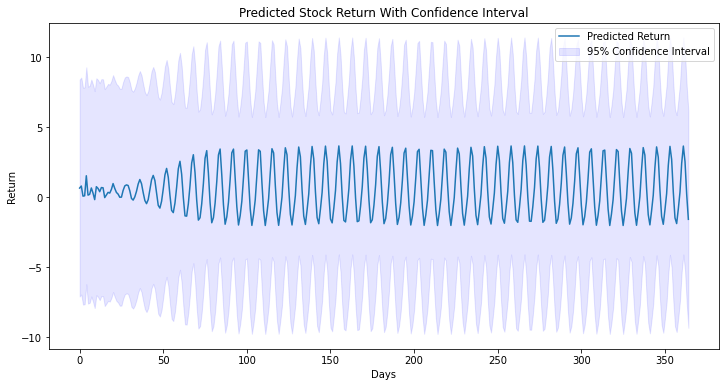

In [44]:
import numpy as np

y_train_pred = svr.predict(X_train)
train_errors = y_train - y_train_pred
error_std = np.std(train_errors)
confidence_interval = 1.96 * error_std  # 95% 置信区间
forecast_df['upper_bound'] = forecast_df['pred_return'] + confidence_interval
forecast_df['lower_bound'] = forecast_df['pred_return'] - confidence_interval
plt.figure(figsize=(12, 6))
plt.plot(forecast_df['pred_return'], label='Predicted Return')
plt.fill_between(forecast_df.index, forecast_df['lower_bound'], forecast_df['upper_bound'], color='b', alpha=0.1, label='95% Confidence Interval')
plt.title("Predicted Stock Return With Confidence Interval")
plt.xlabel("Days")
plt.ylabel("Return")
plt.legend()
plt.show()

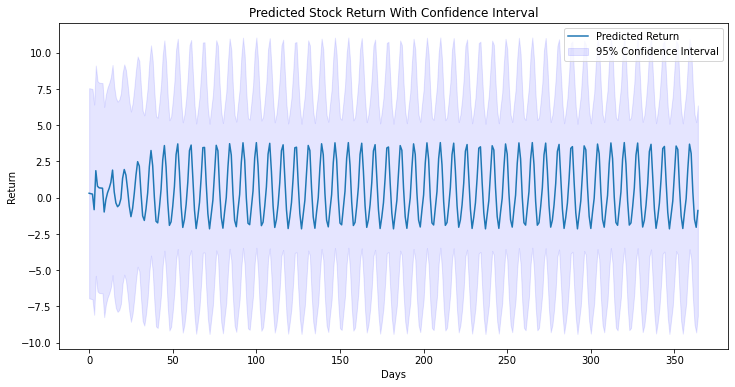

### 线性回归

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn import preprocessing

In [9]:
# 创建新的列, 包含预测值, 根据当前的数据预测5天以后的收盘价
num = 5 # 预测5天后的情况
df['label'] = df['close'].shift(-num) # 预测值
                                     
print(df.shape)

(610, 15)


In [10]:
# 丢弃 'label', 'price_change', 'p_change', 不需要它们做预测（这几个特征和其他特征是线性相关的，如果使用解析解可能导致无解）
Data = df.drop(['label', 'price_change', 'p_change'],axis=1)
Data.tail()

,open,high,close,low,volume,ma5,ma10,ma20,v_ma5,v_ma10,v_ma20,turnover
date,,,,,,,,,,,,
2021-02-04,24.18,25.24,24.60,24.04,1255247.50,24.094,23.325,22.305,1662037.10,1354133.53,1405017.87,0.65
2021-02-05,24.60,25.31,24.93,24.27,1015575.62,24.462,23.615,22.559,1617100.55,1363247.66,1396022.99,0.52
2021-02-08,24.90,24.90,24.80,24.10,1084264.62,24.512,23.846,22.780,1538905.60,1368837.59,1360713.36,0.56
2021-02-09,24.79,24.84,24.58,24.17,942093.50,24.772,24.067,22.959,1244090.55,1350374.89,1343409.76,0.49
2021-02-10,24.60,24.96,23.82,23.38,1918867.00,24.546,24.141,23.115,1243209.65,1412846.32,1386897.13,0.99


In [11]:
X = Data.values
X = preprocessing.scale(X)
X = X[:-num]

df.dropna(inplace=True)
Target = df.label
y = Target.values

print(np.shape(X), np.shape(y))

(605, 12) (605,)


In [12]:
# 将数据分为训练数据和测试数据
X_train, y_train = X[0:550, :], y[0:550]
X_test, y_test = X[550:, -51:], y[550:606]
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(550, 12)
(550,)
(55, 12)
(55,)


In [13]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr.score(X_test, y_test) # 使用绝对系数 R^2 评估模型

0.6782530475708501

In [14]:
# 做预测 

X_Predict = X[-num:]
Forecast = lr.predict(X_Predict)
print(Forecast)
print(y[-num:])
print(X_Predict)

[22.38309392 22.62845455 24.09895794 22.89266393 24.43696297]
[24.6  24.93 24.8  24.58 23.82]
[[ 2.85523438  2.82789771  2.83128761  2.86989739 -0.41864435  2.81546265
   2.83561962  2.53392653 -0.08691692  0.71559499  0.99296656 -0.50877418]
 [ 2.86520807  2.94413378  2.92360951  2.95822128  0.29027169  2.88666164
   2.90751704  2.60098632  0.06938535  0.36824955  1.04426298  0.17489638]
 [ 2.9283748   3.41230686  3.40500224  2.95482421  0.72545946  3.0250295
   2.97115829  2.70785165  0.29054475  0.1772584   1.03143265  0.58509871]
 [ 3.05470827  3.12494545  2.98625651  3.02616274  2.46807248  3.08615316
   3.00349493  2.79929682  0.92869667  0.50602446  1.12806447  2.26009157]
 [ 3.08795391  3.47365367  3.53689066  3.18582518  1.55522057  3.21175893
   3.08880861  2.89612112  1.24004948  0.68593129  1.12616802  1.37131985]]


### 画预测结果

In [15]:
# 预测 2019-05-13 到 2019-05-17 , 一共 5 天的收盘价 
trange = pd.date_range('2019-05-13', periods=num, freq='d')
trange

DatetimeIndex(['2019-05-13', '2019-05-14', '2019-05-15', '2019-05-16',
               '2019-05-17'],
              dtype='datetime64[ns]', freq='D')

In [16]:
# 产生预测值dataframe
Predict_df = pd.DataFrame(Forecast, index=trange)
Predict_df.columns = ['forecast']
Predict_df

,forecast
2019-05-13,22.383094
2019-05-14,22.628455
2019-05-15,24.098958
2019-05-16,22.892664
2019-05-17,24.436963


In [17]:
# 将预测值添加到原始dataframe
df = pd.read_csv('./000001.csv') 
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
# 按照时间升序排列
df.sort_values(by=['date'], inplace=True, ascending=True)
df_concat = pd.concat([df, Predict_df], axis=1)

df_concat = df_concat[df_concat.index.isin(Predict_df.index)]
df_concat.tail(num)

,open,high,close,low,volume,price_change,p_change,ma5,ma10,ma20,v_ma5,v_ma10,v_ma20,turnover,forecast
2019-05-13,12.33,12.54,12.30,12.23,741917.75,-0.38,-3.00,12.538,13.143,13.637,1107915.51,1191640.89,1211461.61,0.43,22.383094
2019-05-14,12.20,12.75,12.49,12.16,1182598.12,0.19,1.54,12.446,12.979,13.585,1129903.46,1198753.07,1237823.69,0.69,22.628455
2019-05-15,12.58,13.11,12.92,12.57,1103988.50,0.43,3.44,12.510,12.892,13.560,1155611.00,1208209.79,1254306.88,0.64,24.098958
2019-05-16,12.93,12.99,12.85,12.78,634901.44,-0.07,-0.54,12.648,12.767,13.518,971160.96,1168630.36,1209357.42,0.37,22.892664
2019-05-17,12.92,12.93,12.44,12.36,965000.88,-0.41,-3.19,12.600,12.626,13.411,925681.34,1153473.43,1138638.70,0.56,24.436963


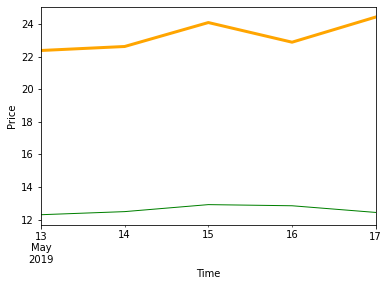

In [18]:
# 画预测值和实际值

df_concat['close'].plot(color='green', linewidth=1)
df_concat['forecast'].plot(color='orange', linewidth=3)
plt.xlabel('Time')
plt.ylabel('Price')
plt.show()

In [19]:
# 理解模型
for idx, col_name in enumerate(['open', 'high', 'close', 'low', 'volume', 'ma5', 'ma10', 'ma20', 'v_ma5', 'v_ma10', 'v_ma20']):
    print("The coefficient for {} is {}".format(col_name, lr.coef_[idx]))

The coefficient for open is 0.25078601689300795
The coefficient for high is -0.15789730901607957
The coefficient for close is 3.1435566793203256
The coefficient for low is -0.4043825103197147
The coefficient for volume is 0.6128563947579092
The coefficient for ma5 is 0.06068595159642709
The coefficient for ma10 is -0.28253026733061937
The coefficient for ma20 is 0.26790007424490225
The coefficient for v_ma5 is -0.13118695211124343
The coefficient for v_ma10 is 0.050767494184378925
The coefficient for v_ma20 is -0.04207946588597445
